In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


import kagglehub


/kaggle/input/datasets/ladkevinkumar/global-energy-mix/global_energy_mix.csv


In [2]:

%pip install -q --no-deps squarify


Note: you may need to restart the kernel to use updated packages.


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import squarify

from pathlib import Path
from IPython.display import display, FileLink

output_dir = Path('/kaggle/working/figures')
output_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120


In [7]:

file_path = '/kaggle/input/datasets/ladkevinkumar/global-energy-mix/global_energy_mix.csv'

df = pd.read_csv(file_path)

source_category = {
    'Coal': 'Fossil',
    'Oil': 'Fossil',
    'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon',
    'Hydro': 'Low-carbon',
    'Wind': 'Renewable',
    'Solar': 'Renewable',
    'Other Renewables': 'Renewable'
}

df['Source_Type'] = df['Source'].map(source_category)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (103, 6)


,Country,Region,Source,Share_pct,TWh,Source_Type
0,United States,North America,Coal,10,1015.0,Fossil
1,United States,North America,Oil,35,3220.0,Fossil
2,United States,North America,Natural Gas,34,3083.0,Fossil
3,United States,North America,Nuclear,9,798.0,Low-carbon
4,United States,North America,Hydro,3,339.0,Low-carbon
5,United States,North America,Wind,4,413.0,Renewable
6,United States,North America,Solar,3,325.0,Renewable
7,United States,North America,Other Renewables,2,229.0,Renewable
8,China,Asia,Coal,58,6929.1,Fossil
9,China,Asia,Oil,18,1620.0,Fossil


In [10]:

def draw_treemap(ax, data, levels, colors, x=0, y=0, w=100, h=100, depth=0):
    if not levels or data.empty:
        return

    column = levels[0]
    grouped = data.groupby(column)['TWh'].sum().sort_values(ascending=False)

    sizes = squarify.normalize_sizes(grouped.values, w, h)
    rectangles = squarify.squarify(sizes, x, y, w, h)

    for (name, value), rect in zip(grouped.items(), rectangles):
        rx, ry = rect['x'], rect['y']
        rw, rh = rect['dx'], rect['dy']

        if len(levels) == 1:
            color = colors.get(name, '#2E75B6')

            ax.add_patch(patches.Rectangle(
                (rx, ry), rw, rh,
                facecolor=color,
                edgecolor='white',
                linewidth=1
            ))

            if rw > 7 and rh > 5:
                ax.text(
                    rx + rw / 2, ry + rh / 2,
                    f'{name}\n{value:,.0f} TWh',
                    ha='center', va='center',
                    fontsize=8, color='black',
                    clip_on=True
                )

        else:
            ax.add_patch(patches.Rectangle(
                (rx, ry), rw, rh,
                facecolor='#EEEEEE',
                edgecolor='#777777',
                linewidth=2 if depth == 0 else 1
            ))

            pad = min(2.5, rh * 0.18)

            if rw > 9 and rh > 5:
                ax.text(
                    rx + 1, ry + rh - pad / 2,
                    f'{name} ({value:,.0f} TWh)',
                    ha='left', va='center',
                    fontsize=9 if depth == 0 else 7,
                    fontweight='bold',
                    clip_on=True
                )

            inner_w = max(rw - 1, 0)
            inner_h = max(rh - pad - 0.5, 0)

            if inner_w > 0 and inner_h > 0:
                subset = data[data[column] == name]

                draw_treemap(
                    ax, subset, levels[1:], colors,
                    rx + 0.5, ry + 0.5,
                    inner_w, inner_h, depth + 1
                )

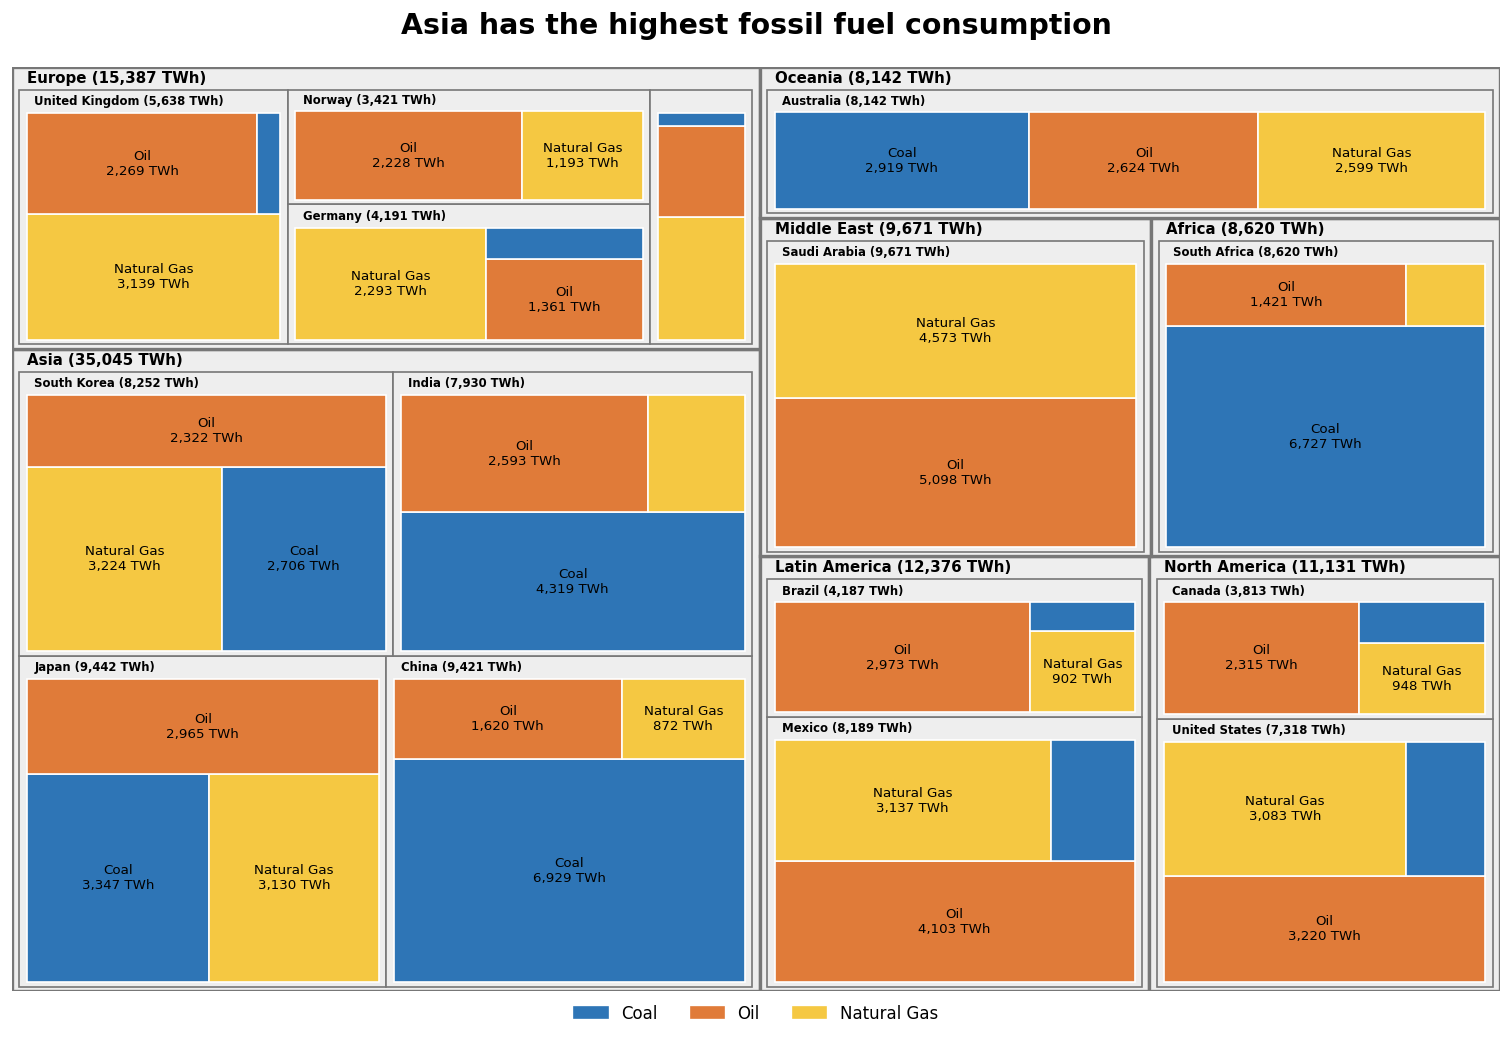

Task 1 PNG saved


In [11]:

df_fossil = df[df['Source_Type'] == 'Fossil'].copy()

fossil_colors = {
    'Coal': '#2E75B6',
    'Oil': '#E07B39',
    'Natural Gas': '#F5C842'
}

region_totals = df_fossil.groupby('Region')['TWh'].sum()
top_region = region_totals.idxmax()

fig1, ax = plt.subplots(figsize=(16, 10))

draw_treemap(
    ax,
    df_fossil,
    ['Region', 'Country', 'Source'],
    fossil_colors
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

ax.set_title(
    f'{top_region} has the highest fossil fuel consumption',
    fontsize=17,
    fontweight='bold',
    pad=20
)

legend_items = [
    patches.Patch(color=color, label=source)
    for source, color in fossil_colors.items()
]

ax.legend(
    handles=legend_items,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    frameon=False
)

plt.savefig(
    output_dir / 'task1_fossil_treemap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Task 1 PNG saved")


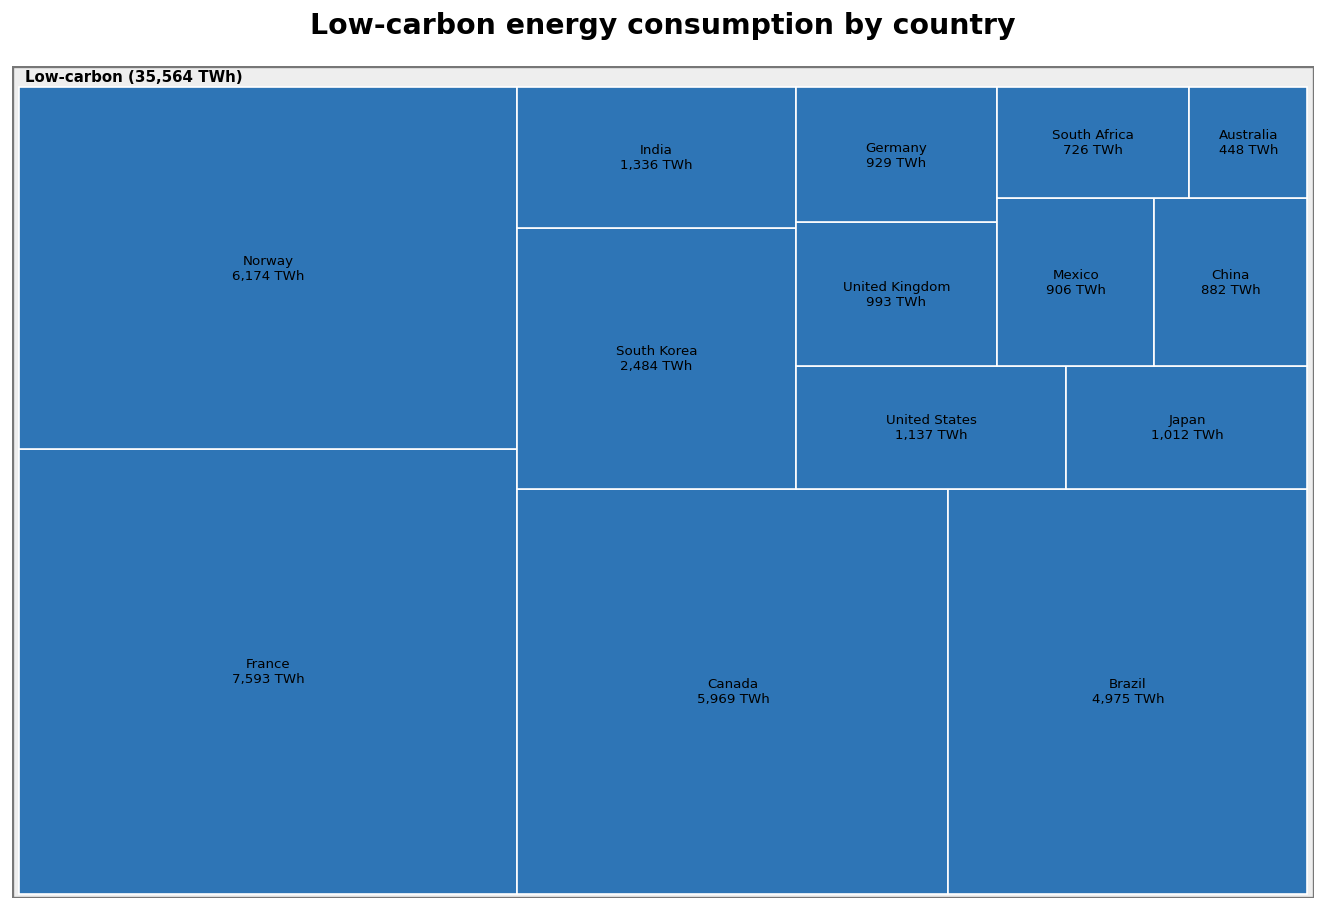

Task 2 treemap PNG saved


In [12]:

df_low = df[df['Source_Type'] == 'Low-carbon'].copy()

low_carbon = (
    df_low.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

low_carbon['All'] = 'Low-carbon'

fig2, ax = plt.subplots(figsize=(14, 9))

low_colors = {
    country: '#2E75B6'
    for country in low_carbon['Country']
}

draw_treemap(
    ax,
    low_carbon,
    ['All', 'Country'],
    low_colors
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')

ax.set_title(
    'Low-carbon energy consumption by country',
    fontsize=17,
    fontweight='bold',
    pad=20
)

plt.savefig(
    output_dir / 'task2_low_carbon_treemap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Task 2 treemap PNG saved")

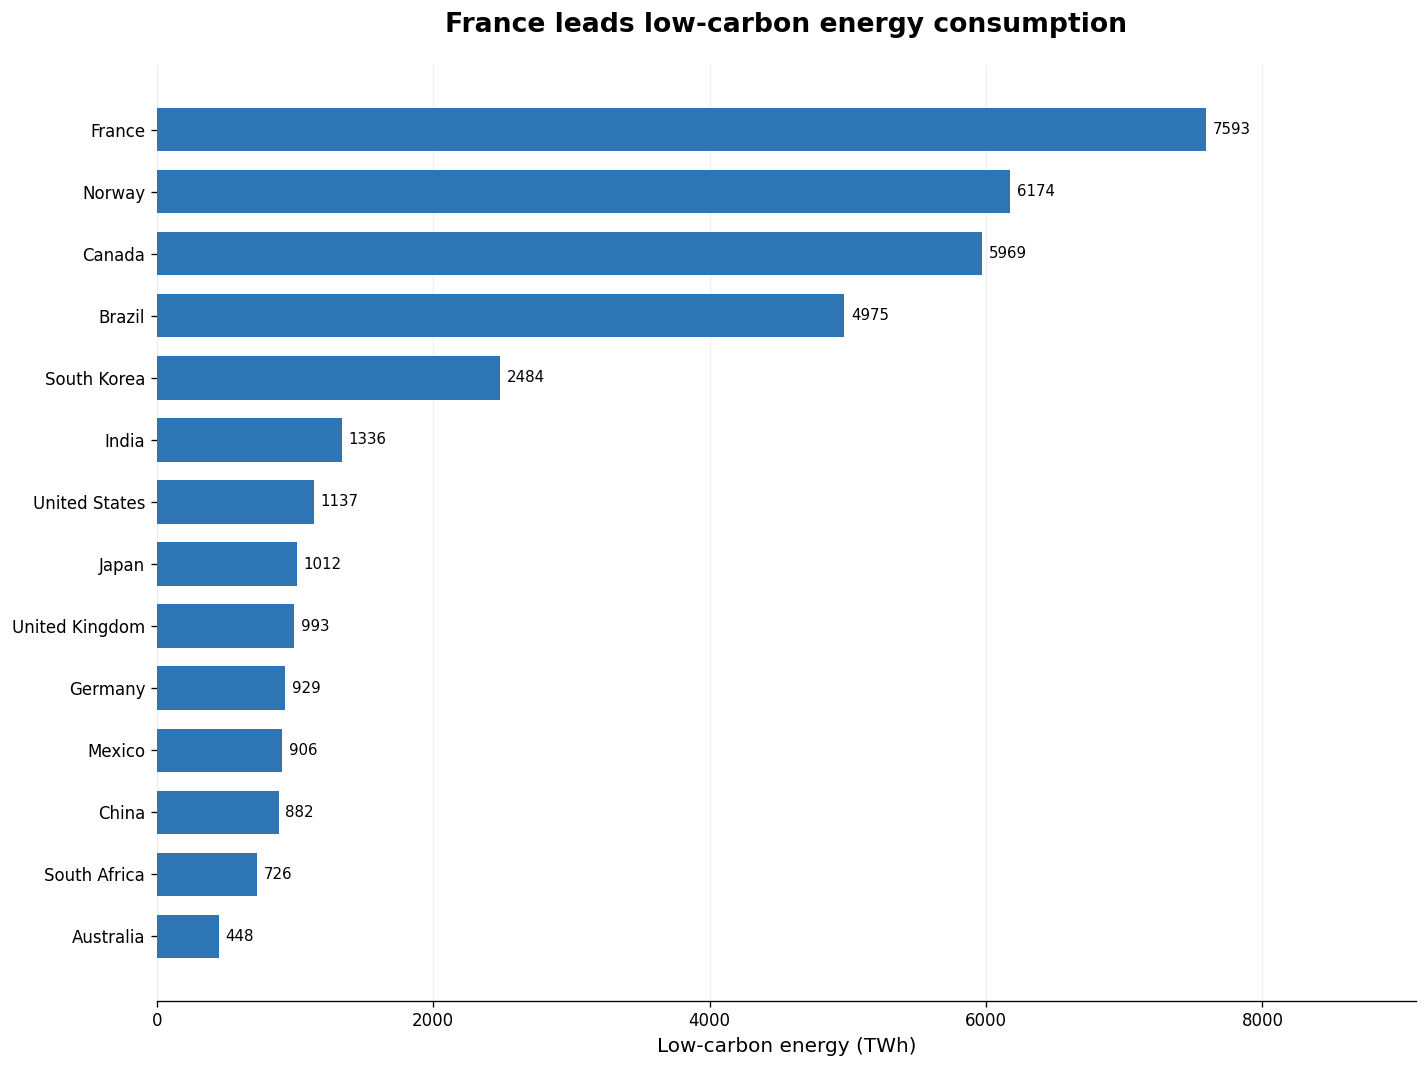

Task 2 bar chart PNG saved


In [13]:

low_carbon_sorted = low_carbon.sort_values('TWh')
top_country = low_carbon.iloc[0]['Country']

fig3, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    low_carbon_sorted['Country'],
    low_carbon_sorted['TWh'],
    color='#2E75B6',
    height=0.7
)

ax.bar_label(
    bars,
    fmt='%.0f',
    padding=4,
    fontsize=9
)

ax.set_title(
    f'{top_country} leads low-carbon energy consumption',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Low-carbon energy (TWh)', fontsize=12)
ax.set_ylabel('')

ax.set_xlim(0, low_carbon_sorted['TWh'].max() * 1.2)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

ax.spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()

plt.savefig(
    output_dir / 'task2_low_carbon_bar.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Task 2 bar chart PNG saved")


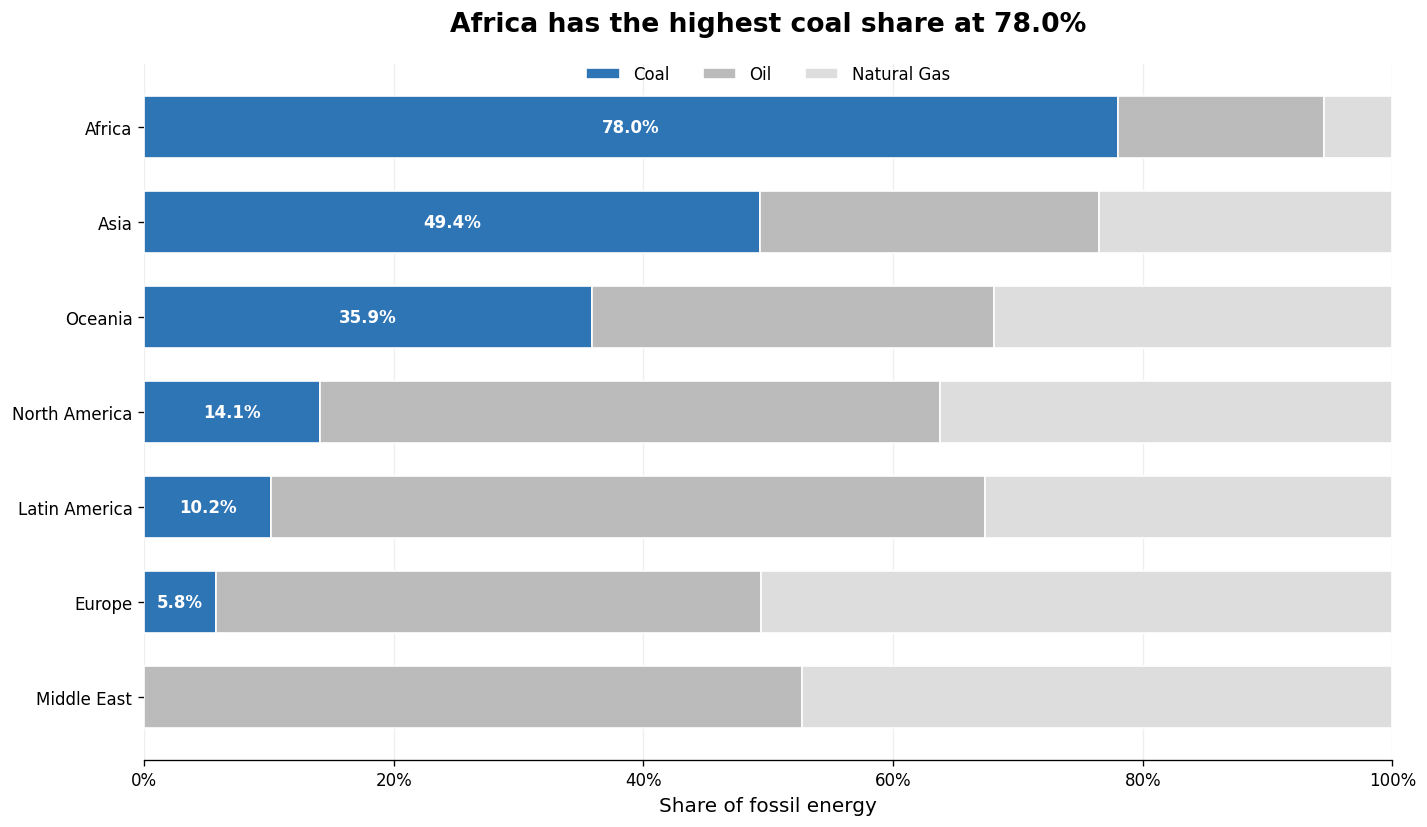

Task 3 PNG saved


In [14]:

region_mix = (
    df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh']
    .sum()
)

region_mix['Share'] = (
    region_mix['TWh'] /
    region_mix.groupby('Region')['TWh'].transform('sum')
)

mix_table = region_mix.pivot(
    index='Region',
    columns='Source',
    values='Share'
).fillna(0)

mix_table = mix_table[
    ['Coal', 'Oil', 'Natural Gas']
].sort_values('Coal', ascending=False)

stack_colors = {
    'Coal': '#2E75B6',
    'Oil': '#BBBBBB',
    'Natural Gas': '#DDDDDD'
}

fig4, ax = plt.subplots(figsize=(12, 7))

left = np.zeros(len(mix_table))

for source in ['Coal', 'Oil', 'Natural Gas']:
    values = mix_table[source].values

    bars = ax.barh(
        mix_table.index,
        values,
        left=left,
        color=stack_colors[source],
        label=source,
        height=0.65,
        edgecolor='white'
    )

    if source == 'Coal':
        for bar, value in zip(bars, values):
            if value > 0:
                ax.text(
                    bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.1%}',
                    ha='center',
                    va='center',
                    fontsize=10,
                    fontweight='bold',
                    color='white'
                )

    left += values

top_region = mix_table.index[0]
top_share = mix_table.iloc[0]['Coal']

ax.set_title(
    f'{top_region} has the highest coal share at {top_share:.1%}',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_xlim(0, 1)
ax.invert_yaxis()

ax.set_xticks(np.linspace(0, 1, 6))
ax.set_xticklabels([
    f'{int(x * 100)}%'
    for x in np.linspace(0, 1, 6)
])

ax.set_xlabel('Share of fossil energy', fontsize=12)
ax.set_ylabel('')

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False
)

ax.spines[['top', 'right', 'left']].set_visible(False)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    output_dir / 'task3_coal_share.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Task 3 PNG saved")


In [15]:

png_files = sorted(output_dir.glob('*.png'))

print("Saved PNG files:\n")

for file in png_files:
    print(file.name)
    display(FileLink(str(file)))

print(f"\nTotal PNG files: {len(png_files)} / 4")


Saved PNG files:

task1_fossil_treemap.png


/kaggle/working/figures/task1_fossil_treemap.png

task2_low_carbon_bar.png


/kaggle/working/figures/task2_low_carbon_bar.png

task2_low_carbon_treemap.png


/kaggle/working/figures/task2_low_carbon_treemap.png

task3_coal_share.png


/kaggle/working/figures/task3_coal_share.png


Total PNG files: 4 / 4
